# Model Selection — NYC Taxi Trip Duration

Which model should be served? This notebook shows how `nyc-taxi select` chose it.
It trains nothing: it only reads the latest `select` run from MLflow.

**Before running:** `docker compose up -d postgres mlflow`, then `uv run nyc-taxi all` once.

## 1. Selection rule (set before the results)

**Data:** train Jan 1–20 · validation Jan 21–25 (comparing) · test Jan 26–31 (used once).
**Candidates:** the RF baseline and the 20 Optuna trials. Naive baselines are only references.

1. **Best:** the lowest validation RMSE.
2. **Tied:** all candidates within **1%** of the best.
3. **Winner:** the **smallest model** among the tied ones (ties in size broken by RMSE).

The winner is scored **once** on test, next to the baselines, and registered without an alias.

In [6]:
import io
import os
import sys
from pathlib import Path

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # no progress bars in the outputs

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import mlflow
import pandas as pd
from IPython.display import Image, display

from src import selection, tracking
from src.experiment import MODEL_NAME, TRACKING_URI

mlflow.set_tracking_uri(TRACKING_URI)
try:
    run = tracking.latest_run(selection.SELECT_RUN_NAME)
except LookupError as exc:
    raise SystemExit(str(exc)) from None  # no select run yet: run `uv run nyc-taxi all`
params, metrics, tags = run.data.params, run.data.metrics, run.data.tags
tolerance = float(params.get("rule_tolerance", selection.RMSE_TOLERANCE))


def artifact(name):
    """Local copy of one file logged in the select run."""
    return tracking.download_run_file(run.info.run_id, name)


def show(fig):
    """Display a matplotlib Figure as a PNG."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110)
    display(Image(data=buffer.getvalue()))


print(f"select run {run.info.run_id} ({pd.Timestamp(run.info.start_time, unit='ms'):%Y-%m-%d %H:%M} UTC)")
print(artifact(selection.RULE_FILE).read_text(encoding="utf-8"))

select run d6e5edc83a9048da9843d9027c632c65 (2026-11-20 11:49 UTC)


Model selection policy

Training: January 1-20, 2025
Validation: January 21-25, 2025
Testing: January 26-31, 2025

Candidates:
- Random Forest baseline
- Every Optuna trial

Selection:
1. Find the lowest validation RMSE.
2. Keep candidates within 1% of the best RMSE.
3. Select the smallest serialized model among them.
4. Break size ties using validation RMSE.

The selected model is refitted on the same training
sample using the same random seed.

Only after selection, evaluate on the test set.

Naive baselines are references, not serving candidates.

Register the selected model without changing champion.



## 2. Candidates within 1% of the best (tied)

In [7]:
table = pd.read_csv(artifact(selection.CANDIDATES_FILE))
print(f"{int(table['tied'].sum())} of {len(table)} candidates tied within {tolerance:.0%} of the best validation RMSE")
columns = ["candidate", "winner", "val_rmse", "rmse_vs_best_pct", "val_mae", "model_mb", *selection.PARAM_KEYS]
table.loc[table["tied"], columns].round(4)

9 of 21 candidates tied within 1% of the best validation RMSE


,candidate,winner,val_rmse,rmse_vs_best_pct,val_mae,model_mb,n_estimators,max_depth,min_samples_leaf,max_features
0,trial-1,True,4.4435,0.3366,3.1189,112.3825,50,36,13,0.5
1,trial-15,False,4.4286,0.0000,3.1099,671.2749,200,25,8,0.5
2,trial-16,False,4.4310,0.0532,3.1109,626.4000,200,27,9,0.5
3,trial-14,False,4.4320,0.0761,3.1112,462.9878,150,26,9,0.5
4,trial-17,False,4.4393,0.2404,3.1181,659.5547,200,27,9,0.7
5,trial-12,False,4.4424,0.3108,3.1180,120.9969,50,30,12,0.5
6,trial-11,False,4.4425,0.3129,3.1163,417.6445,200,31,14,0.5
7,trial-10,False,4.4456,0.3833,3.1182,391.1736,200,35,15,0.5
8,trial-13,False,4.4629,0.7742,3.1293,146.8089,100,27,20,0.5


## 3. Validation RMSE vs model size

Left: every Random Forest candidate (grey) with the selected serving model highlighted in blue and
annotated; the dashed line is the RMSE tolerance (best validation RMSE + 1%), so the tied candidates
are the points below it. Right: the naive baselines' validation RMSE, as accuracy references.

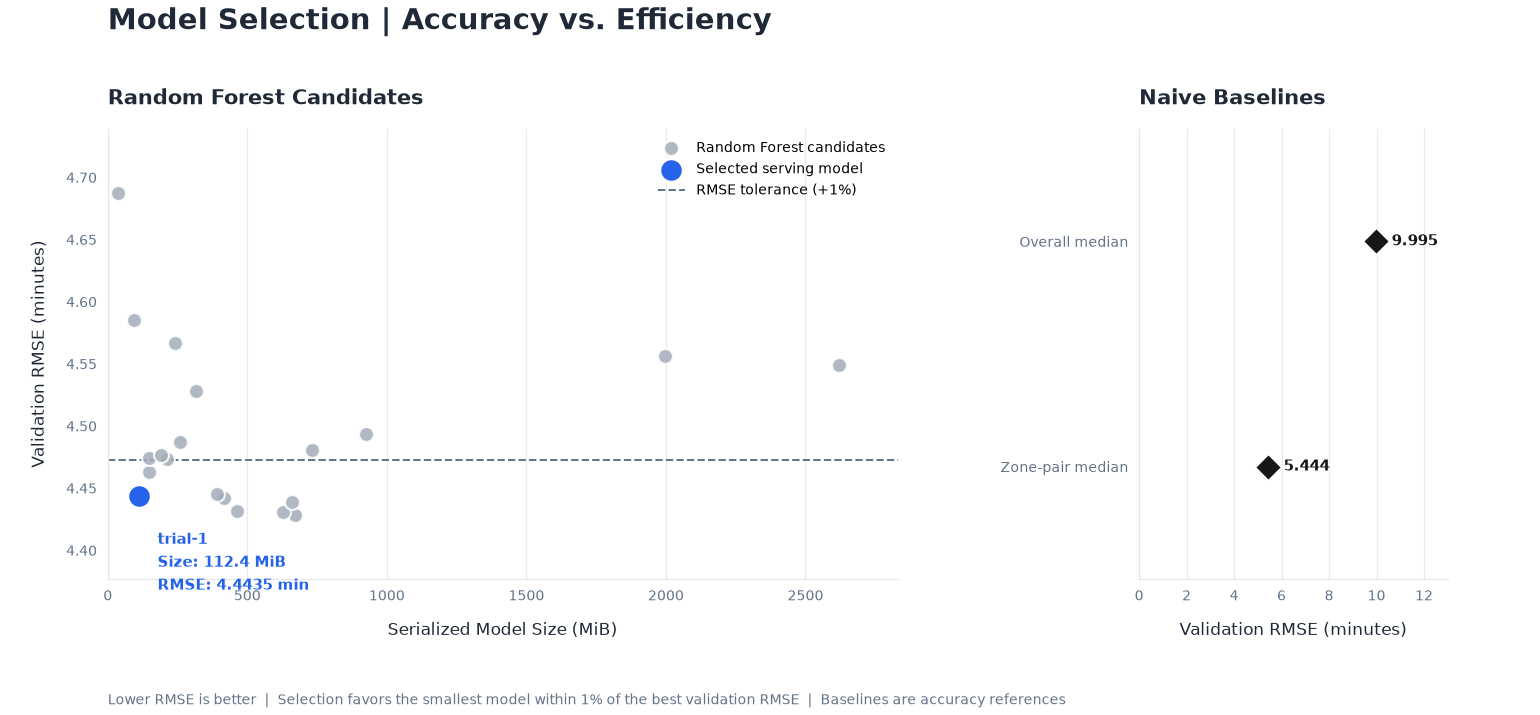

In [8]:
test_table = pd.read_csv(artifact(selection.TEST_FILE), index_col="model")
naive = {label: test_table.at[label, "val_rmse"] for label in selection.NAIVE_LABELS.values() if label in test_table.index}
show(selection.plot_rmse_vs_size(table, tolerance, naive))

## 4. Winner

In [9]:
winner = table[table["winner"]].iloc[0]
print(f"Winner: {winner['candidate']}  {selection.candidate_params(winner)}")
print(f"  validation RMSE {winner['val_rmse']:.4f} ({winner['rmse_vs_best_pct']:+.2f}% vs best), "
      f"MAE {winner['val_mae']:.4f}, size {metrics.get('winner_model_mb', winner['model_mb']):.1f} MiB")
print(f"  test RMSE {metrics['test_rmse']:.4f}, test MAE {metrics['test_mae']:.4f} (scored once)")
print(f"  registered as {MODEL_NAME} version {tags.get('registered_version')} without an alias; "
      f"champion currently -> {tracking.alias_version(MODEL_NAME, 'champion')}")

Winner: trial-1  {'n_estimators': 50, 'max_depth': 36, 'min_samples_leaf': 13, 'max_features': 0.5}
  validation RMSE 4.4435 (+0.34% vs best), MAE 3.1189, size 112.4 MiB
  test RMSE 4.4415, test MAE 3.1041 (scored once)
  registered as nyc-taxi-duration-rf version 8 without an alias; champion currently -> 1


## 5. Final test comparison (Jan 26–31, scored once)

Every row learned from the training days only; the naive baselines use training-day statistics and the
RF baseline is refitted on the same training sample.

,val_rmse,test_rmse,test_mae
model,,,
Overall median,9.9949,10.1225,6.9366
Zone-pair median,5.4437,5.4237,3.6200
RF baseline,4.4771,4.4837,3.1329
Winner (trial-1),4.4435,4.4415,3.1041


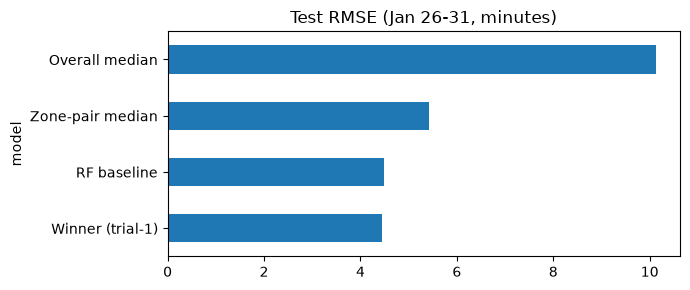

In [10]:
display(test_table[["val_rmse", "test_rmse", "test_mae"]].round(4))
ax = test_table["test_rmse"].plot.barh(figsize=(7, 3), title="Test RMSE (Jan 26-31, minutes)")
ax.invert_yaxis()
ax.figure.tight_layout()

## 6. Feature ladder (validation RMSE, test RMSE, size)

Random Forests with the RF baseline's settings on the same training sample, adding features step by step:
zone IDs only → + zone centers and straight-line distance → all features (`rf-baseline`).
Ladder runs are logged by `nyc-taxi train` (tag `stage=ladder`) and are not selection candidates.
Test RMSE only where `nyc-taxi select` reports it for these rows (the two medians and the selected model);
the medians are lookup rules, so they have no model size.

In [ ]:
from src.baselines import LADDER_RUNS, OVERALL_MEDIAN_RUN, RF_BASELINE_RUN, ZONE_PAIR_MEDIAN_RUN
from src.tuning import TUNING_RUN_NAME

DASH = "–"


def run_metrics(run_name):
    """Metrics of the latest finished run with this name (fails clearly if missing)."""
    try:
        return tracking.latest_run(run_name).data.metrics
    except LookupError as exc:
        raise SystemExit(str(exc)) from None  # e.g. no ladder runs yet: run `uv run nyc-taxi train`


trials = tracking.child_runs(tracking.latest_run(TUNING_RUN_NAME).info.run_id)
best = trials.dropna(subset=["metrics.val_rmse"]).sort_values("metrics.val_rmse").iloc[0]

# label -> (validation RMSE, test RMSE, model size MiB); None is shown as a dash
ladder = {
    "Overall median": (run_metrics(OVERALL_MEDIAN_RUN)["val_rmse"], metrics["test_overall_median_rmse"], None),
    "Zone-pair median": (
        run_metrics(ZONE_PAIR_MEDIAN_RUN)["val_rmse"], metrics["test_zone_pair_median_rmse"], None,
    ),
    **{
        name: (run_metrics(name)["val_rmse"], None, run_metrics(name)["model_mb"])
        for name in [*LADDER_RUNS, RF_BASELINE_RUN]
    },
    f"Best Optuna trial ({best['tags.mlflow.runName']})": (
        best["metrics.val_rmse"], None, best["metrics.model_mb"],
    ),
    f"Selected model ({params['winner']})": (
        metrics["winner_val_rmse"], metrics["test_rmse"], metrics["winner_model_mb"],
    ),
}


def fmt(value, digits):
    return DASH if value is None else f"{value:.{digits}f}"


pd.DataFrame(
    [(fmt(val, 4), fmt(test, 4), fmt(mb, 1)) for val, test, mb in ladder.values()],
    index=pd.Index(ladder, name="model"),
    columns=["validation RMSE", "test RMSE", "model size (MiB)"],
)

**Next:** `uv run nyc-taxi verify <version>`, set the `champion` alias in the MLflow UI, then an
authenticated `/reload` (see `docs/operations.md`). The previous champion stays registered for rollback.